In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Загрузка файла
df = pd.read_csv('titanic.csv')

# 2. Выбор необходимых признаков и целевой переменной
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']
df_selected = df[features].copy()

# 3. Обработка пропущенных значений в Age (заполнение медианой)
median_age = df_selected['Age'].median()
df_selected['Age'] = df_selected['Age'].fillna(median_age)

# 4. Преобразование Sex в числовой формат (male -> 0, female -> 1)
df_selected['Sex'] = df_selected['Sex'].map({'male': 0, 'female': 1})

# 5. Проверка таблицы на отсутствие пропусков и типы данных
print(df_selected.info())
print(df_selected.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Age       891 non-null    float64
 2   Sex       891 non-null    int64  
 3   Fare      891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Survived  891 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 48.9 KB
None
   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0


In [3]:
# Расчёт и округление матрицы корреляции
corr_matrix = df_selected.corr().round(2)
print(corr_matrix)

# Вывод корреляции конкретно с целевой переменной Survived
print("\nКорреляция с Survived:")
print(corr_matrix['Survived'])


          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00

Корреляция с Survived:
Pclass     -0.34
Age        -0.06
Sex         0.54
Fare        0.26
SibSp      -0.04
Parch       0.08
Survived    1.00
Name: Survived, dtype: float64


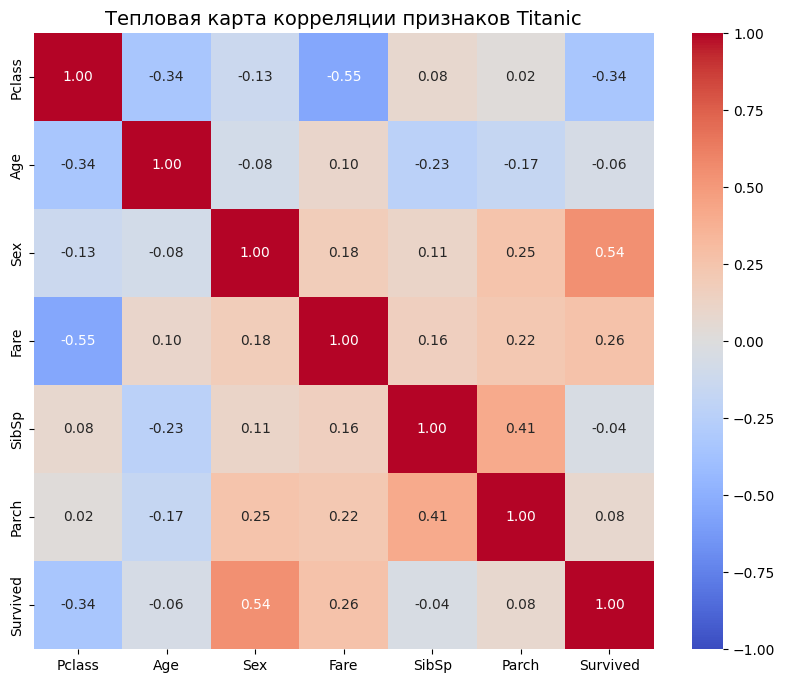

In [4]:
# Задание размера графика
plt.figure(figsize=(10, 8))

# Построение тепловой карты
# data - матрица корреляции
# annot=True - выводит значения коэффициентов внутри ячеек
# cmap - задает цветовую палитру (например, 'coolwarm' или 'RdBu_r')
# fmt - формат вывода чисел (два знака после запятой)
sns.heatmap(data=corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)

# Добавление названия графика
plt.title('Тепловая карта корреляции признаков Titanic', fontsize=14)

# Отображение графика
plt.show()



Ответы на вопросы блока «Корреляция и машинное обучение»

• Какие признаки могут быть наиболее полезны для предсказания Survived?
Наиболее полезными линейными признаками будут Sex (пол) и Pclass (класс каюты), так как они демонстрируют самые высокие модульные значения коэффициента корреляции с целевой переменной. Признак Fare также будет полезен, поскольку он сильно связан с классом обслуживания.
• Можно ли выбирать признаки для модели машинного обучения только на основании корреляции?
Нет, только на основании корреляции выбирать признаки нельзя. На это есть несколько важных причин:
	1. Линейные ограничения: Коэффициент Пирсона оценивает исключительно линейную взаимосвязь. Если связь между признаком (например, Age) и целевой переменной имеет нелинейный характер (допустим, выживали чаще совсем маленькие дети и пожилые люди, а гибли люди среднего возраста), корреляция может быть близка к нулю. Тем не менее, для дерева решений или случайного леса этот признак окажется крайне важным.
	2. Мультиколлинеарность: Два признака могут сильно коррелировать между собой (например, Fare и Pclass). Если включить в модель оба, это может переобучить или исказить линейные модели (например, логистическую регрессию).
	3. Причинно-следственная связь: Как указано в теории задания, корреляция не доказывает причинно-следственную связь. Случайное совпадение в данных может показать ложную корреляцию, которая ухудшит работу модели на новых объектах.
